In [1]:
import polars as pl
import matplotlib.pyplot as plt

from hmci.common.config import load_config

cfg = load_config()
RAW = cfg.paths.raw
pl.Config.set_tbl_rows(20)
print(RAW, [p.name for p in RAW.iterdir()])

Matplotlib is building the font cache; this may take a moment.


/Users/itsharshitmittal/hm-customer-intel/data/raw ['customers.csv', 'articles.csv', 'transactions_train.csv']


In [2]:
articles = pl.read_csv(RAW / "articles.csv", schema_overrides={"article_id": pl.Utf8})
customers = pl.read_csv(RAW / "customers.csv")

print("articles:", articles.shape)
print("customers:", customers.shape)
articles.head(3)

articles: (105542, 25)
customers: (1371980, 7)


article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
str,i64,str,i64,str,str,i64,str,i64,str,i64,str,i64,str,i64,str,str,str,i64,str,i64,str,i64,str,str
"""0108775015""",108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",9,"""Black""",4,"""Dark""",5,"""Black""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
"""0108775044""",108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",10,"""White""",3,"""Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
"""0108775051""",108775,"""Strap top (1)""",253,"""Vest top""","""Garment Upper body""",1010017,"""Stripe""",11,"""Off White""",1,"""Dusty Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"


In [3]:
tx = (
    pl.scan_csv(
        RAW / "transactions_train.csv",
        schema_overrides={"article_id": pl.Utf8, "price": pl.Float32, "sales_channel_id": pl.Int8},
        try_parse_dates=True,
    )
    .with_columns(
        pl.col("customer_id").cast(pl.Categorical),
        pl.col("article_id").cast(pl.Categorical),
    )
    .collect(engine="streaming")
)
print(tx.shape, f"{tx.estimated_size('mb'):.0f} MB in memory")
print(tx.schema)

(31788324, 5) 515 MB in memory
Schema([('t_dat', Date), ('customer_id', Categorical), ('article_id', Categorical), ('price', Float32), ('sales_channel_id', Int8)])


In [4]:
summary = tx.select(
    pl.len().alias("rows"),
    pl.col("t_dat").min().alias("first_day"),
    pl.col("t_dat").max().alias("last_day"),
    pl.col("customer_id").n_unique().alias("customers"),
    pl.col("article_id").n_unique().alias("articles"),
)
print(summary)

print(tx["sales_channel_id"].value_counts(normalize=True))

# do IDs keep a leading zero? (expect all length 10)
print(articles["article_id"].str.len_chars().value_counts())

shape: (1, 5)
┌──────────┬────────────┬────────────┬───────────┬──────────┐
│ rows     ┆ first_day  ┆ last_day   ┆ customers ┆ articles │
│ ---      ┆ ---        ┆ ---        ┆ ---       ┆ ---      │
│ u32      ┆ date       ┆ date       ┆ u32       ┆ u32      │
╞══════════╪════════════╪════════════╪═══════════╪══════════╡
│ 31788324 ┆ 2018-09-20 ┆ 2020-09-22 ┆ 1362281   ┆ 104547   │
└──────────┴────────────┴────────────┴───────────┴──────────┘
shape: (2, 2)
┌──────────────────┬────────────┐
│ sales_channel_id ┆ proportion │
│ ---              ┆ ---        │
│ i8               ┆ f64        │
╞══════════════════╪════════════╡
│ 2                ┆ 0.704028   │
│ 1                ┆ 0.295972   │
└──────────────────┴────────────┘
shape: (1, 2)
┌────────────┬────────┐
│ article_id ┆ count  │
│ ---        ┆ ---    │
│ u32        ┆ u32    │
╞════════════╪════════╡
│ 10         ┆ 105542 │
└────────────┴────────┘


In [5]:
key = ["t_dat", "customer_id", "article_id", "price", "sales_channel_id"]
dupes = tx.group_by(key).len().filter(pl.col("len") > 1)
print("rows that are repeats:", (dupes["len"] - 1).sum())
print(dupes["len"].value_counts().sort("len").head(10))

rows that are repeats: 2974905
shape: (10, 2)
┌─────┬─────────┐
│ len ┆ count   │
│ --- ┆ ---     │
│ u32 ┆ u32     │
╞═════╪═════════╡
│ 2   ┆ 2285073 │
│ 3   ┆ 177237  │
│ 4   ┆ 55412   │
│ 5   ┆ 9259    │
│ 6   ┆ 8181    │
│ 7   ┆ 1733    │
│ 8   ┆ 2132    │
│ 9   ┆ 911     │
│ 10  ┆ 1112    │
│ 11  ┆ 380     │
└─────┴─────────┘


shape: (1, 7)
┌─────────────┬────────┬────────┬────────────────────┬───────────────────────┬───────┬─────────────┐
│ customer_id ┆ FN     ┆ Active ┆ club_member_status ┆ fashion_news_frequenc ┆ age   ┆ postal_code │
│ ---         ┆ ---    ┆ ---    ┆ ---                ┆ y                     ┆ ---   ┆ ---         │
│ u32         ┆ u32    ┆ u32    ┆ u32                ┆ ---                   ┆ u32   ┆ u32         │
│             ┆        ┆        ┆                    ┆ u32                   ┆       ┆             │
╞═════════════╪════════╪════════╪════════════════════╪═══════════════════════╪═══════╪═════════════╡
│ 0           ┆ 895050 ┆ 907576 ┆ 6062               ┆ 16009                 ┆ 15861 ┆ 0           │
└─────────────┴────────┴────────┴────────────────────┴───────────────────────┴───────┴─────────────┘
shape: (4, 2)
┌────────────────────┬─────────┐
│ club_member_status ┆ count   │
│ ---                ┆ ---     │
│ str                ┆ u32     │
╞════════════════════╪═════════╡

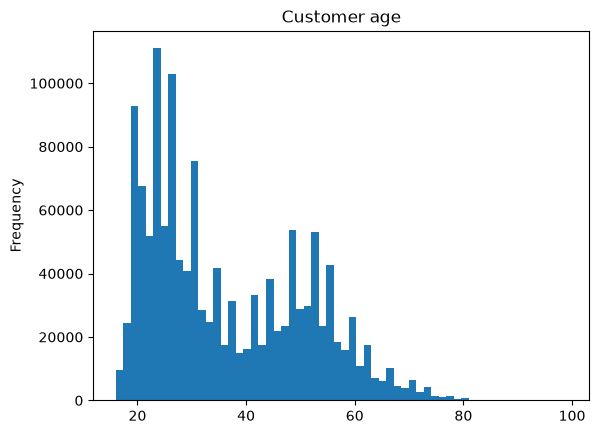

In [6]:
print(customers.null_count())
print(customers["club_member_status"].value_counts())
print(customers["fashion_news_frequency"].value_counts())

customers["age"].drop_nulls().to_pandas().plot.hist(bins=60, title="Customer age")
plt.show()

In [7]:
print(articles.select(pl.all().n_unique()).transpose(include_header=True, column_names=["n_unique"]))

sold = tx.select(pl.col("article_id").cast(pl.Utf8).unique())
never_sold = articles.join(sold, on="article_id", how="anti")
print("articles never sold:", never_sold.height)

shape: (25, 2)
┌───────────────────────────┬──────────┐
│ column                    ┆ n_unique │
│ ---                       ┆ ---      │
│ str                       ┆ u32      │
╞═══════════════════════════╪══════════╡
│ article_id                ┆ 105542   │
│ product_code              ┆ 47224    │
│ prod_name                 ┆ 45875    │
│ product_type_no           ┆ 132      │
│ product_type_name         ┆ 131      │
│ product_group_name        ┆ 19       │
│ graphical_appearance_no   ┆ 30       │
│ graphical_appearance_name ┆ 30       │
│ colour_group_code         ┆ 50       │
│ colour_group_name         ┆ 50       │
│ …                         ┆ …        │
│ department_name           ┆ 250      │
│ index_code                ┆ 10       │
│ index_name                ┆ 10       │
│ index_group_no            ┆ 5        │
│ index_group_name          ┆ 5        │
│ section_no                ┆ 57       │
│ section_name              ┆ 56       │
│ garment_group_no          ┆ 21       │
│

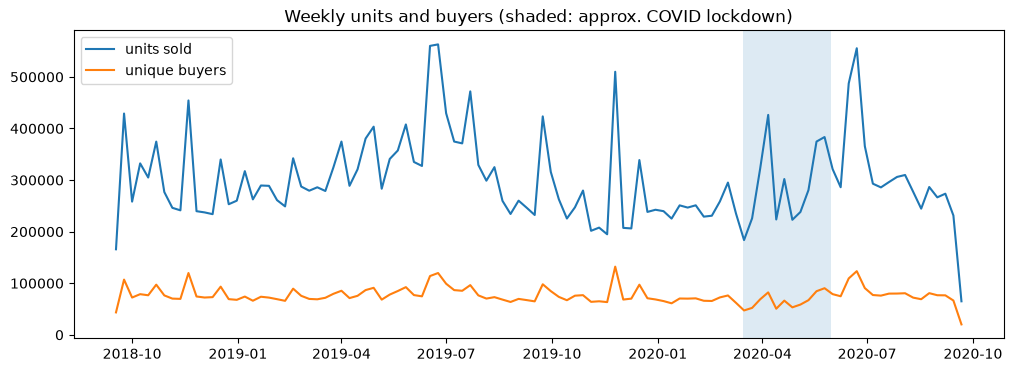

In [10]:
import datetime
weekly = (
    tx.group_by(pl.col("t_dat").dt.truncate("1w").alias("week"))
    .agg(pl.len().alias("units"), pl.col("customer_id").n_unique().alias("buyers"))
    .sort("week")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly["week"], weekly["units"], label="units sold")
ax.plot(weekly["week"], weekly["buyers"], label="unique buyers")
ax.axvspan(datetime.date(2020, 3, 15), datetime.date(2020, 5, 31), alpha=0.15)
ax.set_title("Weekly units and buyers (shaded: approx. COVID lockdown)")
ax.legend(); plt.show()

In [11]:
print(tx["price"].describe())

shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 3.1788324e7 │
│ null_count ┆ 0.0         │
│ mean       ┆ 0.027829    │
│ std        ┆ 0.019181    │
│ min        ┆ 0.000017    │
│ 25%        ┆ 0.015814    │
│ 50%        ┆ 0.025407    │
│ 75%        ┆ 0.033881    │
│ max        ┆ 0.591525    │
└────────────┴─────────────┘


50th percentile gap: 22 days (3.1 weeks)
75th percentile gap: 58 days (8.3 weeks)
90th percentile gap: 124 days (17.7 weeks)
95th percentile gap: 187 days (26.7 weeks)


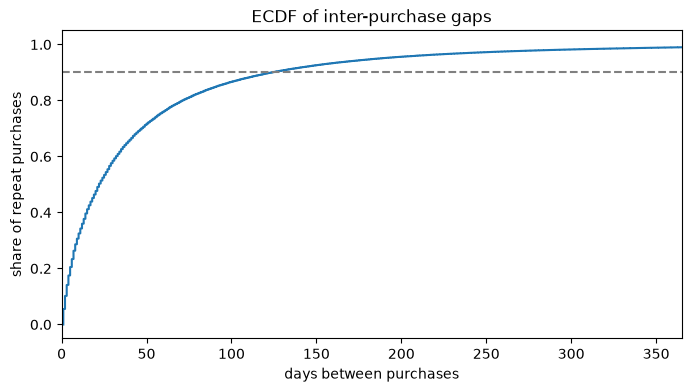

In [12]:
visits = tx.select("customer_id", "t_dat").unique()

gaps = (
    visits.sort(["customer_id", "t_dat"])
    .with_columns(gap_days=pl.col("t_dat").diff().over("customer_id").dt.total_days())
    .drop_nulls("gap_days")
)

qs = [0.5, 0.75, 0.9, 0.95]
gap_q = {q: gaps["gap_days"].quantile(q) for q in qs}
for q, d in gap_q.items():
    print(f"{int(q*100)}th percentile gap: {d:.0f} days ({d/7:.1f} weeks)")

x = gaps["gap_days"].sort()
y = pl.int_range(1, x.len() + 1, eager=True) / x.len()
plt.figure(figsize=(8, 4))
plt.plot(x, y)
plt.axhline(0.9, ls="--", c="grey")
plt.xlim(0, 365)
plt.xlabel("days between purchases"); plt.ylabel("share of repeat purchases")
plt.title("ECDF of inter-purchase gaps"); plt.show()

In [13]:
per_cust = visits.group_by("customer_id").len(name="purchase_days")
print(per_cust["purchase_days"].describe())
one_timers = (per_cust["purchase_days"] == 1).mean()
print(f"one-time buyers: {one_timers:.1%}")

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1.362281e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 6.665423   │
│ std        ┆ 9.707005   │
│ min        ┆ 1.0        │
│ 25%        ┆ 1.0        │
│ 50%        ┆ 3.0        │
│ 75%        ┆ 8.0        │
│ max        ┆ 427.0      │
└────────────┴────────────┘
one-time buyers: 32.9%
